# 01 - Exploratory Data Analysis: Credit Card Default

**Goal:** understand the data before modelling, and record decisions that the training code depends on.
Run the cells in order, then **share the outputs you see** so we can interpret them together. Nothing here has been run on the real data yet.

Prerequisite: `python scripts/download_data.py`

In [1]:
import sys
sys.path.insert(0, "..")  # so `import creditguard` works from the notebooks folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from creditguard import config
from creditguard.data import load_raw

sns.set_theme(style="whitegrid")
df = load_raw(config.DATA_PATH)
df.shape

(30000, 24)

## 1. Schema, types and missing values
UCI lists no missing values and 30,000 rows. **Check that yourself.**

In [2]:
df.info()
print("Missing values per column:\n", df.isna().sum()[df.isna().sum() > 0])
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   EDUCATION  30000 non-null  int64
 2   PAY_1      30000 non-null  int64
 3   PAY_2      30000 non-null  int64
 4   PAY_3      30000 non-null  int64
 5   PAY_4      30000 non-null  int64
 6   PAY_5      30000 non-null  int64
 7   PAY_6      30000 non-null  int64
 8   BILL_AMT1  30000 non-null  int64
 9   BILL_AMT2  30000 non-null  int64
 10  BILL_AMT3  30000 non-null  int64
 11  BILL_AMT4  30000 non-null  int64
 12  BILL_AMT5  30000 non-null  int64
 13  BILL_AMT6  30000 non-null  int64
 14  PAY_AMT1   30000 non-null  int64
 15  PAY_AMT2   30000 non-null  int64
 16  PAY_AMT3   30000 non-null  int64
 17  PAY_AMT4   30000 non-null  int64
 18  PAY_AMT5   30000 non-null  int64
 19  PAY_AMT6   30000 non-null  int64
 20  SEX        30000 non-null  int64
 21  AGE        30000 non-nu

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
PAY_1,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0
PAY_6,30000.0,-0.291100,1.149988,-2.0,-1.00,0.0,0.00,8.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.00,964511.0
BILL_AMT2,30000.0,49179.075167,71173.768783,-69777.0,2984.75,21200.0,64006.25,983931.0


## 2. Duplicates and invalid values

In [3]:
print("Duplicate rows:", df.duplicated().sum())
print("Non-positive credit limits:", (df['LIMIT_BAL'] <= 0).sum())
print("Negative payment amounts:", (df[config.PAYAMT_COLS] < 0).sum().sum())
print("Negative bill amounts (credit balances):", (df[config.BILL_COLS] < 0).sum().sum())

Duplicate rows: 35
Non-positive credit limits: 0
Negative payment amounts: 0
Negative bill amounts (credit balances): 3932


## 3. Categorical columns and undocumented codes
The UCI description documents EDUCATION 1-4 and MARRIAGE 1-3, but other analyses report extra codes (EDUCATION 0, 5, 6; MARRIAGE 0) and repayment-status values (-2, 0) not in the description.
`clean_data()` currently folds EDUCATION 0/5/6 into 4. **That is an assumption: confirm the counts here.**

In [4]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(df[col].value_counts().sort_index(), "\n")
print(df["PAY_1"].value_counts().sort_index())

SEX
1    11888
2    18112
Name: count, dtype: int64 

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64 

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64 

PAY_1
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64


## 4. Target distribution and class imbalance

default
0    23364
1     6636
Name: count, dtype: int64 
Default rate: 0.221


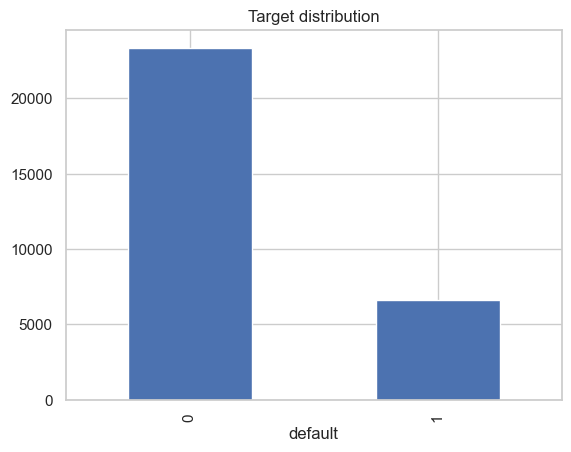

In [5]:
rate = df[config.TARGET].mean()
print(df[config.TARGET].value_counts(), f"\nDefault rate: {rate:.3f}")
df[config.TARGET].value_counts().plot(kind="bar", title="Target distribution")
plt.show()

**Decision to record:** if the default rate is well below 50%, accuracy is a misleading metric (a model that predicts "no default" for everyone scores high). That is why the project uses PR-AUC, recall/precision at a threshold and cost.

## 5. Univariate analysis

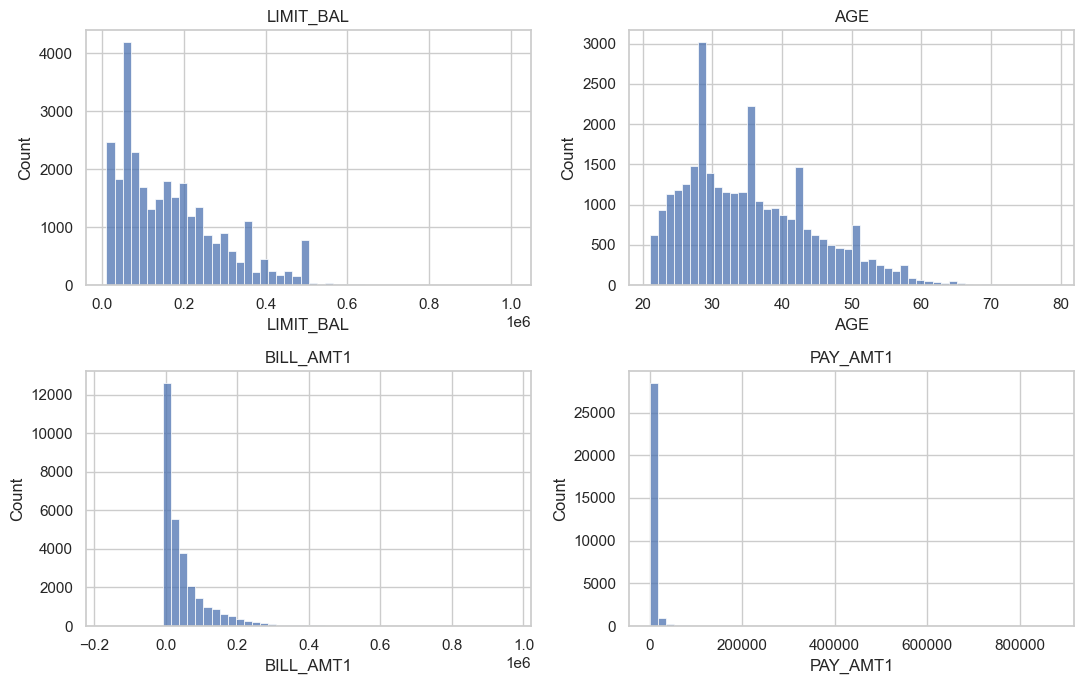

In [6]:
num_cols = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

In [7]:
# Heavy right tails? Compare mean and median, and look at the extreme quantiles.
df[["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]].describe(percentiles=[.5, .9, .99]).T

,count,mean,std,min,50%,90%,99%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,140000.0,360000.0,500000.00,1000000.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,22381.5,142133.7,350110.68,964511.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,2100.0,10300.0,66522.18,873552.0


## 6. Bivariate analysis: what relates to default?

In [8]:
# Default rate by most recent repayment status: expected to be the strongest signal
df.groupby("PAY_1")[config.TARGET].agg(["mean", "count"]).rename(columns={"mean": "default_rate"})

,default_rate,count
PAY_1,,
-2,0.132294,2759
-1,0.167781,5686
0,0.128113,14737
1,0.339479,3688
2,0.691414,2667
3,0.757764,322
4,0.684211,76
5,0.500000,26
6,0.545455,11


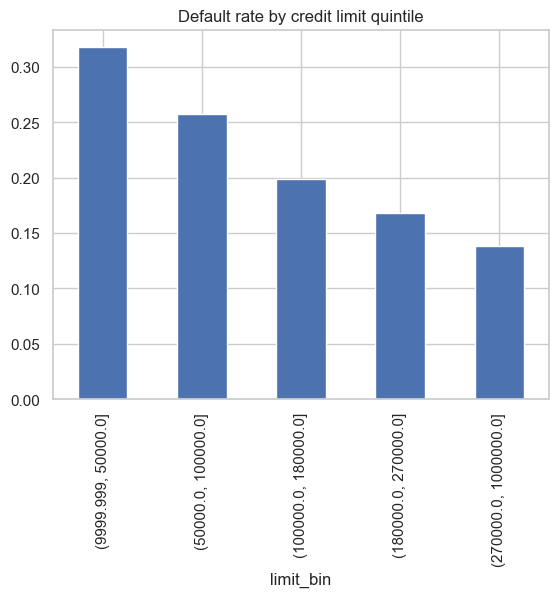

In [9]:
# Default rate by credit-limit quintile
df["limit_bin"] = pd.qcut(df["LIMIT_BAL"], 5, duplicates="drop")
df.groupby("limit_bin", observed=True)[config.TARGET].mean().plot(kind="bar", title="Default rate by credit limit quintile")
plt.show()

In [10]:
# Audit-only attributes: look, but remember they are NOT model inputs
for col in ["SEX", "MARRIAGE"]:
    print(df.groupby(col)[config.TARGET].agg(["mean", "count"]), "\n")
df["age_band"] = pd.cut(df["AGE"], [0, 29, 39, 49, 200], labels=["<30", "30-39", "40-49", "50+"])
print(df.groupby("age_band", observed=True)[config.TARGET].agg(["mean", "count"]))

         mean  count
SEX                 
1    0.241672  11888
2    0.207763  18112 

              mean  count
MARRIAGE                 
0         0.092593     54
1         0.234717  13659
2         0.209283  15964
3         0.260062    323 

              mean  count
age_band                 
<30       0.228426   9618
30-39     0.202527  11238
40-49     0.229734   6464
50+       0.252985   2680


## 7. Multivariate: correlations and multicollinearity

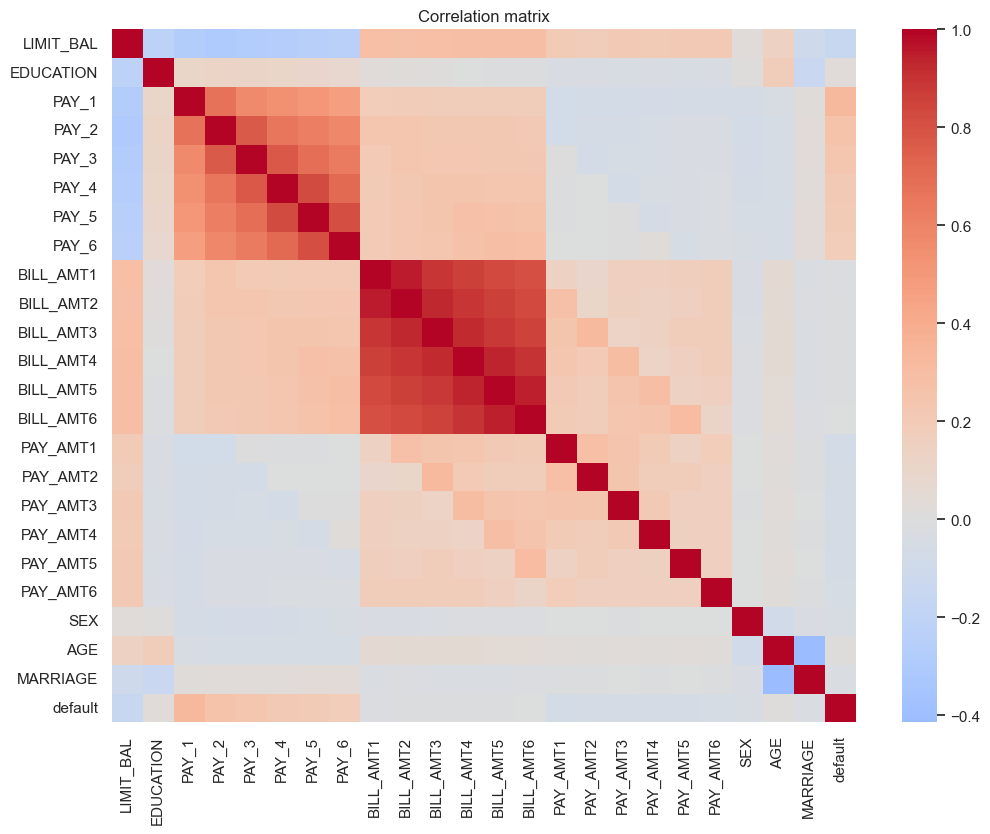

default      1.000000
PAY_1        0.324794
PAY_2        0.263551
PAY_3        0.235253
PAY_4        0.216614
PAY_5        0.204149
PAY_6        0.186866
EDUCATION    0.028006
AGE          0.013890
BILL_AMT6   -0.005372
BILL_AMT5   -0.006760
BILL_AMT4   -0.010156
BILL_AMT3   -0.014076
BILL_AMT2   -0.014193
BILL_AMT1   -0.019644
MARRIAGE    -0.024339
SEX         -0.039961
PAY_AMT6    -0.053183
PAY_AMT5    -0.055124
PAY_AMT3    -0.056250
PAY_AMT4    -0.056827
PAY_AMT2    -0.058579
PAY_AMT1    -0.072929
LIMIT_BAL   -0.153520
Name: default, dtype: float64

In [11]:
corr = df.drop(columns=["limit_bin", "age_band"]).corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()
corr[config.TARGET].sort_values(ascending=False)

Expect BILL_AMT1..6 to be highly correlated with each other. That is a reason to engineer trend/average features and to regularise, not to drop them blindly.

## 8. Leakage check
Questions to answer from the data description, then write your answers here:
1. Do all PAY_/BILL_AMT/PAY_AMT columns describe months **before** the target month? (UCI: April to September 2005, target = default next month.)
2. Is any column derived from the target? (Look at suspiciously strong single-feature relationships.)
3. Are there duplicate customers that could straddle train and test? (See the duplicate count in section 2.)

In [12]:
# Single-feature ROC-AUC: a value near 1.0 for any one feature would be a red flag.
from sklearn.metrics import roc_auc_score
single = {c: roc_auc_score(df[config.TARGET], df[c]) for c in config.INPUT_COLUMNS}
pd.Series(single).sub(0.5).abs().add(0.5).sort_values(ascending=False).head(8)

PAY_1        0.689710
PAY_2        0.638553
PAY_3        0.624346
LIMIT_BAL    0.617803
PAY_AMT1     0.611317
PAY_4        0.609655
PAY_AMT2     0.604693
PAY_5        0.599511
dtype: float64

## 9. Reproducible split
The training script carves off a stratified 20% test set (`random_state=42`) BEFORE any modelling and never touches it until the final evaluation. Confirm the class balance is preserved:

In [13]:
from sklearn.model_selection import train_test_split
tr, te = train_test_split(df, test_size=config.TEST_SIZE, stratify=df[config.TARGET], random_state=config.RANDOM_STATE)
print(len(tr), len(te), tr[config.TARGET].mean().round(4), te[config.TARGET].mean().round(4))

24000 6000 0.2212 0.2212


## 10. Findings to write up (fill in after running)
- Data quality issues found:
- Class imbalance:
- Strongest predictors:
- Cleaning decisions confirmed or changed:
- Leakage concerns:
- Modelling decisions this analysis supports:

In [14]:
# 1. Duplicates: what are they, and do they straddle the train/test split?
dups = df[df.duplicated(keep=False)].sort_values(list(df.columns))
print("rows involved in duplication:", len(dups))
print("share that are all-zero bills AND payments:",
      (dups[config.BILL_COLS + config.PAYAMT_COLS] == 0).all(axis=1).mean().round(3))
display(dups.head(10))

cols = config.INPUT_COLUMNS + config.AUDIT_COLUMNS + [config.TARGET]
print("test rows also present in train:",
      pd.merge(te[cols].drop_duplicates(), tr[cols].drop_duplicates(), how="inner").shape[0])

# 2. Default rate by EDUCATION code
print(df.groupby("EDUCATION")[config.TARGET].agg(["mean", "count"]))

# 3. Customers with any negative bill
neg = (df[config.BILL_COLS] < 0).any(axis=1)
print("customers with a negative bill:", neg.sum(),
      "| default rate with:", df.loc[neg, config.TARGET].mean().round(3),
      "| without:", df.loc[~neg, config.TARGET].mean().round(3))

rows involved in duplication: 70
share that are all-zero bills AND payments: 0.857


,LIMIT_BAL,EDUCATION,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,...,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,SEX,AGE,MARRIAGE,default,limit_bin,age_band
12430,20000,2,2,2,4,4,4,4,1650,1650,...,0,0,0,0,1,24,2,1,"(9999.999, 50000.0]",<30
14294,20000,2,2,2,4,4,4,4,1650,1650,...,0,0,0,0,1,24,2,1,"(9999.999, 50000.0]",<30
7170,50000,1,1,-2,-2,-2,-2,-2,0,0,...,0,0,0,0,2,23,2,0,"(9999.999, 50000.0]",<30
17032,50000,1,1,-2,-2,-2,-2,-2,0,0,...,0,0,0,0,2,23,2,0,"(9999.999, 50000.0]",<30
1759,50000,2,1,-2,-2,-2,-2,-2,0,0,...,0,0,0,0,1,26,2,0,"(9999.999, 50000.0]",<30
10250,50000,2,1,-2,-2,-2,-2,-2,0,0,...,0,0,0,0,1,26,2,0,"(9999.999, 50000.0]",<30
21768,80000,2,-2,-2,-2,-2,-2,-2,0,0,...,0,0,0,0,2,25,2,0,"(50000.0, 100000.0]",<30
27765,80000,2,-2,-2,-2,-2,-2,-2,0,0,...,0,0,0,0,2,25,2,0,"(50000.0, 100000.0]",<30
7366,80000,2,-2,-2,-2,-2,-2,-2,0,0,...,0,0,0,0,2,31,1,0,"(50000.0, 100000.0]",30-39
19114,80000,2,-2,-2,-2,-2,-2,-2,0,0,...,0,0,0,0,2,31,1,0,"(50000.0, 100000.0]",30-39


test rows also present in train: 7
               mean  count
EDUCATION                 
0          0.000000     14
1          0.192348  10585
2          0.237349  14030
3          0.251576   4917
4          0.056911    123
5          0.064286    280
6          0.156863     51
customers with a negative bill: 1930 | default rate with: 0.165 | without: 0.225


In [15]:
cols = config.INPUT_COLUMNS + config.AUDIT_COLUMNS + [config.TARGET]
print("test rows also present in train:",
      pd.merge(te[cols].drop_duplicates(), tr[cols].drop_duplicates(), how="inner").shape[0])

print(df.groupby("EDUCATION")[config.TARGET].agg(["mean", "count"]))

neg = (df[config.BILL_COLS] < 0).any(axis=1)
print("customers with a negative bill:", neg.sum(),
      "| default rate with:", df.loc[neg, config.TARGET].mean().round(3),
      "| without:", df.loc[~neg, config.TARGET].mean().round(3))

test rows also present in train: 7
               mean  count
EDUCATION                 
0          0.000000     14
1          0.192348  10585
2          0.237349  14030
3          0.251576   4917
4          0.056911    123
5          0.064286    280
6          0.156863     51
customers with a negative bill: 1930 | default rate with: 0.165 | without: 0.225
